# Accroche
Quand un humain laisse tomber une balle, son cerveau ne calcule pas la trajectoire avec des équations.
Il a un "modèle" intuitif de comment la balle se comportera. C'est son "modèle du monde" et c'est exactement l'idée derrière les world models en IA : apprendre à un agent à se construire une représentation interne de son environnement, pour pouvoir imaginer ce qui va se passer avant que ça arrive.

# Le problème que ça résout
Jusque là, pour modéliser un agent qui évolue dns un environnement on utilisait des techniques en dure comme le reinforcement learning.
Le problème, il faut des millions voir des milliards d'interactions pour apprendre, c'est lent, coûteux, parfois dangereux (voiture autonome qui doit "essayer" de percuter un mur pour apprendre que c'est mauvais). 
Quand on y pense, un humain sait qu'une chute depuis une falaise serait fatale. Il n'a pas besoin de la faire pour le savoir (heureusement).
Le world model permet d'apprendre en imagination, dans une simulation interne.

## 1. Le formalisme des World Models

### 1.1 Définition générale

Un **world model** est un modèle qui apprend une représentation interne de la dynamique d'un environnement, afin de prédire un état futur à partir d'observations passées, d'une action, et éventuellement d'une variable latente. LeCun (2022) et Ha & Schmidhuber (2018) formalisent cela ainsi :

$$
s(t+1) = F\big(s(t),\ x(t),\ a(t),\ z(t)\big) \tag{1}
$$

où :
- $x(t)$ est l'**observation** reçue à l'instant $t$ (une frame vidéo, un token, un signal sensoriel...)
- $s(t)$ est une **estimation de l'état** du monde à l'instant $t$ (souvent construite à partir des observations passées)
- $a(t)$ est une **action** prise par l'agent à l'instant $t$ (pertinent en RL / robotique)
- $z(t)$ est une **variable latente**, capturant l'incertitude ou les facteurs non observés
- $F$ est la fonction — c'est elle qu'on va apprendre avec un réseau de neurones

C'est l'équation la plus générale : elle couvre aussi bien un modèle de dynamique en RL (avec actions) qu'un modèle prédictif purement passif.

### 1.2 Simplification : pas d'action, pas de variable latente

La plupart des world models utilisés en NLP (LLMs), en vision (modèles de génération vidéo) ou en audio n'ont **ni action ni variable latente explicite** on ne contrôle pas le "prochain mot" ou la "prochaine frame" avec une action externe. L'équation (1) se réduit alors à :

$$
s(t+1) = F\big(x(1), x(2), \dots, x(t),\ a(t)\big) \tag{2}
$$

où l'état $s(t)$ est directement encodé par l'**historique des observations** $x(1), \dots, x(t)$, plus besoin de le représenter séparément.

### 1.3 Le cas des modèles autorégressifs (TAM)

En supprimant également l'action (puisqu'un LLM ou un modèle vidéo génératif ne reçoit pas d'action externe), on obtient la formulation qui va nous intéresser directement dans ce notebook :

$$
x(t+1) = F\big(x(1), x(2), \dots, x(t)\big) \tag{3}
$$

où $\big(x(1), \dots, x(t)\big)$ est appelé le **contexte**. C'est très exactement ce que font :

| Domaine | $x(i)$ | $F$ |
|---|---|---|
| NLP (LLM) | token | Transformer causal, prédit $p(x_{t+1} \mid x_{1:t})$ |
| Vision (vidéo) | frame / embedding de frame | vision Transformer / RNN, prédit la frame suivante |
| Audio | unité de parole discrétisée | Transformer autorégressif |

**C'est cette équation (3) que notre TAM va apprendre à approximer** dans ce notebook : étant donné une séquence d'embeddings vidéo passés $x(1), \dots, x(t)$, prédire directement $x(t+1)$.

### 1.4 Où EBM et TAM divergent

Le formalisme ci-dessus ne dit **rien** sur *comment* $F$ doit être paramétrée ni *où* la prédiction doit être produite. C'est précisément là que TAM et EBM (qu'on a présenté dans 01_Energie_Based_models.ipynb) prennent deux chemins différents pour approximer le même $F$ :

**TAM : prédiction directe dans l'espace de sortie.**
Le réseau apprend directement une fonction paramétrique $f_\theta$ qui retourne l'état prédit :

$$
\hat{x}(t+1) = f_\theta\big(x(1), \dots, x(t)\big)
$$

Un seul forward pass, la sortie $\hat{x}(t+1)$ *est* la prédiction. Aucune notion de "à quel point cette prédiction est plausible", le réseau ne fait qu'un mapping entrée → sortie.

**EBM : évaluation de la compatibilité dans l'espace d'entrée.**
Le réseau n'apprend pas à produire $x(t+1)$ directement, mais une fonction d'énergie $E_\theta$ qui mesure la compatibilité entre le contexte et un état futur *candidat* $\hat{x}$ :

$$
E_\theta\big(x(1), \dots, x(t),\ \hat{x}\big) \in \mathbb{R}
$$

avec $E_\theta$ faible si $\hat{x}$ est un futur plausible, élevé sinon. La prédiction n'est plus un simple forward pass mais le résultat d'une **minimisation** :

$$
\hat{x}(t+1) = \arg\min_{\hat{x}} E_\theta\big(x(1), \dots, x(t),\ \hat{x}\big)
$$

résolue itérativement par descente de gradient / MCMC (ce qu'on détaillera dans le notebook EBWM).

### 1.5 Pourquoi cette distinction est le cœur de l'article

Formellement, TAM et EBWM approximent tous les deux la **même équation (3)**. La différence n'est donc pas dans *ce qu'ils modélisent*, mais dans *comment ils le modélisent* :

- **TAM** : $F$ = une fonction directe entrée → sortie, appliquée une seule fois.
- **EBWM** : $F$ = le résultat d'une optimisation sur une fonction de compatibilité, appliquée itérativement.

Cette différence architecturale est exactement ce qui, selon les auteurs, permet à EBWM (mais pas au TAM) de posséder les quatre facettes cognitives introduites en §1 du papier (l'influence des prédictions sur l'état interne, l'évaluation de la plausibilité, L'allocation dynamique de ressource et la modélisation de l'incertitude ) puisque prédire *dans l'espace d'entrée* et *évaluer une énergie* sont deux choses qu'un simple forward pass ne peut pas faire.


Je vais modeliser ici une balle qui se déplace dans une boîte 2D ( par exemple [0,1]X[0,1]) à vitesse constante entre deux rebonds. 
Pour la modélisation on se basera uniquement sur l'état observé $x(t) = (p_x(t), p_y(t)) \in R$. On ne donne jamais la vitesse explicitement au modèle.

**Contexte** :  une fenêtre glissante des k dernières positions  ctx $(k) = (x(1):x(k))$

**Futur candidat** : $\hat{x}(k+1) \in R²$

**Energie à apprendre** : $E_{\theta}(ctx(k), \hat{x}(k+1) \in R$ 

faible si $\hat{x}(k+1)$ est cohérent avec la trajectoire physique (vitesse constante, ou rebond correct si le contexte montre qu'on approche d'un bord), élevé sinon.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [2]:
seed = 42
rng = np.random.default_rng(seed)
box=(0.0, 1.0)
pos = rng.uniform(box[0] + 0.1, box[1] - 0.1, size=2)
print(pos)

[0.71916484 0.45110275]


In [3]:
def simulate_bouncing_ball(n_steps=500,speed = 0.4, dt=0.02, box=(0.0, 1.0), seed=None):
    """
    Simule une balle rebondissant dans une boîte [box[0], box[1]]^2.
    Retourne uniquement les positions (n_steps, 2) -- la vitesse
    n'est jamais exposée, elle doit être inférée du contexte.

    #n_steps : combien de points (positions successives) on veut générer dans la trajectoire
    
    #speed = 0.4  : vitesse de la balle (constante)
    
    #dt ("delta time") : le pas de temps entre deux positions — plus il est petit, plus la balle avance "doucement" à chaque étape
    
    #box : les limites de la boîte dans laquelle la balle rebondit, ici de 0.0 à 1.0 sur chaque axe
    
    #seed : une graine aléatoire, pour la reproductibilité des résultats
    """

    rng = np.random.default_rng(seed) # Generateur(PCG64), je ne sais pas trop ce que c'est...
    pos = rng.uniform(box[0] + 0.1, box[1] - 0.1, size=2) # on tire uniformément deux réels entre 0.1 et 0.9 pour en faire un point de départ
    # vitesse aléatoire mais de norme fixe, pour garder une dynamique homogène
    angle = rng.uniform(0, 2 * np.pi) # un angle entre 0 et 2pi pour la direction de départ
                          
    vel = speed * np.array([np.cos(angle), np.sin(angle)]) # vecteur vitesse initial (v_x, v_y)

    positions = [pos.copy()] # liste des positions en partant de la pos initiale
    for _ in range(n_steps - 1):  #n-1 étapes
        pos = pos + vel * dt       # équation horaire
        for d in range(2):         # gestion d'obstacle
            if pos[d] < box[0]:     # vérifie si la balle dépasse le bord inférieur/gauche 
                pos[d] = box[0] + (box[0] - pos[d])
                vel[d] *= -1          # inverse le sens de la vitesse sur cet axe (rebond
            elif pos[d] > box[1]:
                pos[d] = box[1] - (pos[d] - box[1])
                vel[d] *= -1
        positions.append(pos.copy())   # concatenation

    return np.stack(positions)  # (n_steps, 2)

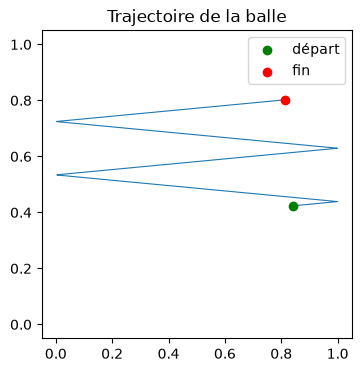

In [4]:
traj = simulate_bouncing_ball(n_steps=500,speed = 0.4, dt=0.02, box=(0.0, 1.0), seed=None)

plt.figure(figsize=(4, 4))
plt.plot(traj[:, 0], traj[:, 1], lw=0.8)
plt.scatter(traj[0, 0], traj[0, 1], c="green", label="départ", zorder=5)
plt.scatter(traj[-1, 0], traj[-1, 1], c="red", label="fin", zorder=5)
plt.xlim(-0.05, 1.05); plt.ylim(-0.05, 1.05)
plt.legend(); plt.title("Trajectoire de la balle")
plt.show()

In [5]:
print(traj.shape) # 500 points de la trajectoire dans le plan 2D

(500, 2)


In [6]:
class EBM(nn.Module):
    def __init__(self, input_dim=2, hidden_dims=[64], output_dim=1):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.SiLU())
            prev_dim = h
        layers.append(nn.Linear(prev_dim, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x, y):
        return self.net(torch.cat([x, y], dim=-1))

In [7]:
def make_positive_pairs(traj, context_len=3):
    """
    Extrait les paires positives (contexte, vrai futur) depuis la trajectoire.
    x = contexte aplati, y = vrai x(t+1).
    """
    contexts, true_nexts = [], []
    n = len(traj)

    for t in range(context_len - 1, n - 1):
        ctx = traj[t - context_len + 1 : t + 1]   # (context_len, 2)
        true_next = traj[t + 1]                    # (2,)
        contexts.append(ctx.flatten())
        true_nexts.append(true_next)

    return (torch.tensor(np.stack(contexts), dtype=torch.float32),
            torch.tensor(np.stack(true_nexts), dtype=torch.float32))

ctx, true_next = make_positive_pairs(traj)
print(ctx.shape, true_next.shape)

torch.Size([497, 6]) torch.Size([497, 2])


Sur 500 données on récupère 497 pour l'entrainement car on perd les 1er, 2eme et 3eme données qui n'ont pas assez de contexte puisque la taille de contexte est fixé à 3.

In [8]:
def sample_negatives_ball(ebm, x, n_steps=20, step_size=0.1, noise_scale=0.01):
    """
    Génère des négatifs adversariaux par Langevin dynamics
    y est une position 2D.
    x = contexte aplati (batch, context_len*2)
    n_steps est le nombre d'ittération dans la dynamique de Langevin
    step_size est la vitesse de descente du grad
    noise_scale est l'échelle de bruit qu'on ajoute à y pour fabriquer des false_next
    Sortie : autant de données labélisées false qu'il y a de context dans x
    """
    y = torch.empty(x.shape[0], 2).uniform_(-1.5, 1.5).requires_grad_(True)
    for _ in range(n_steps):
        E = ebm(x, y).sum()
        grad_y, = torch.autograd.grad(E, y)
        noise = torch.randn_like(y) * noise_scale
        y = (y - step_size * grad_y + noise).detach().requires_grad_(True)
        y = torch.clamp(y, 0.0, 1.0) # restreint y à la boîte
    return y.detach()


In [17]:
def train_ball_ebm(ebm, traj, context_len=3, n_epochs=2000, n_steps=20, step_size=0.1, lr=1e-3, reg_weight=0.01, batch_size=64, noise_scale=0.01):
    opt = torch.optim.Adam(ebm.parameters(), lr=lr)

    contexts, true_nexts = make_positive_pairs(traj, context_len=context_len)
    n_samples = contexts.shape[0]

    for epoch in range(n_epochs):
        idx = torch.randint(0, n_samples, (batch_size,))
        x_batch = contexts[idx]
        y_pos = true_nexts[idx]

        y_neg = sample_negatives_ball(ebm, x_batch, step_size=step_size, n_steps=n_steps, noise_scale = noise_scale)

        E_pos = ebm(x_batch, y_pos)
        E_neg = ebm(x_batch, y_neg)

        contrastive = torch.relu(1.0 + E_pos - E_neg).mean()
        reg = reg_weight * (E_pos**2 + E_neg**2).mean()
        loss = contrastive + reg

        opt.zero_grad()
        loss.backward()
        opt.step()

        if epoch % 200 == 0:
            print(f"epoch {epoch:5d} | loss {loss.item():.4f} | E_pos {E_pos.mean().item():.3f} | E_neg {E_neg.mean().item():.3f} | |E_neg-E_pos| {torch.abs(E_neg.mean() - E_pos.mean()).item():.3f}")

In [10]:
def predict_next_via_energy_descent(ebm, context, n_steps=20, lr=0.05):
    """
    context : tensor (context_len, 2), positions passées non aplaties.
    """
    candidate = context[-1].clone().unsqueeze(0).requires_grad_(True)  # init = dernière position
    x = context.flatten().unsqueeze(0)

    for _ in range(n_steps):
        energy = ebm(x, candidate)
        grad = torch.autograd.grad(energy.sum(), candidate)[0]
        candidate = (candidate - lr * grad).detach().requires_grad_(True)

    return candidate.detach().squeeze(0)

In [11]:
context_len = 3
input_dim = context_len * 2 + 2   # taille de x + taille de y après concaténation = 8

ebm_shallow = EBM(input_dim=input_dim, hidden_dims=[64])           # version light

In [12]:
false_next = sample_negatives_ball(ebm_shallow,ctx)
print(false_next.size())

torch.Size([497, 2])


In [13]:
train_ball_ebm(ebm_shallow, traj)

epoch     0 | loss 1.0036 | E_pos -0.218 | E_neg -0.221 | |E_neg-E_pos| 0.003
epoch   200 | loss 0.9914 | E_pos 0.000 | E_neg 0.009 | |E_neg-E_pos| 0.009
epoch   400 | loss 0.9923 | E_pos -0.000 | E_neg 0.007 | |E_neg-E_pos| 0.008
epoch   600 | loss 0.9966 | E_pos -0.006 | E_neg -0.002 | |E_neg-E_pos| 0.003
epoch   800 | loss 0.9948 | E_pos -0.003 | E_neg 0.002 | |E_neg-E_pos| 0.005
epoch  1000 | loss 0.9972 | E_pos -0.000 | E_neg 0.003 | |E_neg-E_pos| 0.003
epoch  1200 | loss 0.9973 | E_pos 0.003 | E_neg 0.006 | |E_neg-E_pos| 0.003
epoch  1400 | loss 0.9986 | E_pos 0.002 | E_neg 0.004 | |E_neg-E_pos| 0.001
epoch  1600 | loss 0.9988 | E_pos -0.002 | E_neg -0.001 | |E_neg-E_pos| 0.001
epoch  1800 | loss 0.9989 | E_pos -0.002 | E_neg -0.001 | |E_neg-E_pos| 0.001


La loss plafonne autour de 0.99, quasi égale à 1.0, et $E_{pos}$ tout comme $E_{neg}$
oscillent tout proche de 0. C'est un signe de collapse. Le modèle n'apprend pas à séparer positifs et négatifs, il apprend juste à mettre toutes les énergies à 0.
Le "collapse" (effondrement), c'est quand le modèle trouve une solution paresseuse qui fait baisser la loss sans avoir réellement appris ce qu'on voulait lui apprendre.

Revenons un instant sur les mathématiques de l'étape d'apprentissage.

**loss = contrastive + reg_weight * $(E_{pos}² + E_{neg}²)$.mean()**

Quand on fait loss.backward(), PyTorch calcule le gradient de toute cette somme par rapport aux poids du réseau. Concrètement, ça revient à additionner deux gradients qui tirent dans des directions différentes :

$$\nabla_{\theta} \mathcal{L} = \nabla_{\theta} \mathcal{L}_{\text{contrastive}} + \text{reg\_weight} \cdot \nabla_{\theta} \left( E_{\text{pos}}^2 + E_{\text{neg}}^2 \right)$$

* **$\nabla_{\theta} \mathcal{L}_{\text{contrastive}}$** : sépare les énergies
* **$\text{reg\_weight} \cdot \nabla_{\theta} \left( E_{\text{pos}}^2 + E_{\text{neg}}^2 \right)$** : ramène les énergies vers 0 pour éviter les divergences vers + et - l'infini


### Le rôle de chaque terme ("politique")

* **Le terme contrastif** pousse les poids dans la direction qui augmente l'écart $E_{\text{neg}} - E_{\text{pos}}$. Sa seule préoccupation est la différence relative entre positif et négatif — il se fiche complètement de savoir si les valeurs absolues sont à $0$, $-50$ ou $+200$.
* **Le terme de régularisation** pousse les poids dans la direction qui ramène $E_{\text{pos}}$ et $E_{\text{neg}}$ vers $0$, peu importe leur écart relatif. Il n'a aucune notion de "positif" ou "négatif" — il traite les deux exactement pareil et veut juste que la norme soit faible.
* **`reg_weight`** est le curseur qui décide de l'importance de la deuxième politique par rapport à la première dans la somme des gradients. C'est un simple facteur multiplicatif : plus il est grand, plus la mise à jour des poids à chaque pas est dominée par "ramener vers 0" plutôt que par "séparer".


### Ce qui se passe concrètement à chaque step

* **`reg_weight` élevé :** À chaque `opt.step()`, la correction "ramène vers 0" est numériquement plus grande que la correction "sépare". Le réseau apprend plus vite à satisfaire la régularisation qu'à satisfaire le contrastif. Il converge vers la solution la plus facile pour la régularisation (tout à $0$), c'est le **collapse**.
* **`reg_weight = 0` :** La politique de mise à jour ignore complètement la contrainte de valeur absolue. Seul le contrastif dirige les poids. Rien n'empêche les énergies de dériver arbitrairement loin de $0$ au fil des époques (instabilité potentielle, mais pas de collapse).
* **`reg_weight` bien choisi (petit) :** La régularisation agit comme un léger garde-fou en arrière-plan. Elle n'intervient significativement que si les énergies s'éloignent trop de $0$, sans jamais dominer la mise à jour au point d'empêcher le contrastif de faire son travail de séparation. Alors au vu de toutes ces explications je vais énoncer des hypothèses sur les causes possibles.

**Les causes possibles:**

1- **Le poids de régularisation est trop fort relativement au signal contrastif.**
**reg_weight=0.01** peut sembler petit, mais si les négatifs générés par Langevin ne sont pas assez "difficiles" informatifs au début, le seul moyen facile de réduire la loss totale est de pousser toutes les énergies vers 0. La régularisation "gagne" contre le terme contrastif.

2- **Les négatifs ne sont peut-être pas assez éloignés des positifs pour donner un signal utile.**

3-**Le réseau est peut-être trop petit / pas assez expressif**

**hidden_dims=[64]**, une seule couche cachée pour apprendre une frontière énergie utile sur ce problème à 8 dimensions d'entrée.

Nous allons vérifier chacune de ses hypothèses.

In [14]:
"""
ici je vais désactiver  temporairement la régularisation (reg_weight=0) pour voir si 
$E_{pos}$ et $E_{neg}$ commencent à diverger normalement.
"""
ebm_shallow_1 = EBM(input_dim=input_dim, hidden_dims=[64])
train_ball_ebm(ebm_shallow_1, traj, reg_weight=0.0, n_epochs=2000)

epoch     0 | loss 0.9924 | E_pos -0.238 | E_neg -0.230 | |E_neg-E_pos| 0.008
epoch   200 | loss 0.9953 | E_pos -0.341 | E_neg -0.337 | |E_neg-E_pos| 0.005
epoch   400 | loss 0.9919 | E_pos -0.290 | E_neg -0.282 | |E_neg-E_pos| 0.008
epoch   600 | loss 0.9932 | E_pos -0.263 | E_neg -0.257 | |E_neg-E_pos| 0.007
epoch   800 | loss 0.9954 | E_pos -0.251 | E_neg -0.246 | |E_neg-E_pos| 0.005
epoch  1000 | loss 0.9983 | E_pos -0.239 | E_neg -0.237 | |E_neg-E_pos| 0.002
epoch  1200 | loss 0.9983 | E_pos -0.241 | E_neg -0.239 | |E_neg-E_pos| 0.002
epoch  1400 | loss 0.9985 | E_pos -0.257 | E_neg -0.255 | |E_neg-E_pos| 0.001
epoch  1600 | loss 0.9991 | E_pos -0.246 | E_neg -0.245 | |E_neg-E_pos| 0.001
epoch  1800 | loss 0.9992 | E_pos -0.244 | E_neg -0.243 | |E_neg-E_pos| 0.001


Le problème persiste...
L'hypothèse 1 est invalide. On passe à la 2.

In [53]:
print(torch.hstack([false_next[:10], true_next[:10]]))

tensor([[9.9933e-01, 9.3591e-01, 4.1688e-01, 5.4315e-01],
        [8.1415e-02, 4.2073e-02, 4.1070e-01, 5.4824e-01],
        [2.4389e-01, 0.0000e+00, 4.0453e-01, 5.5333e-01],
        [8.6541e-01, 4.5578e-03, 3.9836e-01, 5.5841e-01],
        [1.3405e-01, 0.0000e+00, 3.9218e-01, 5.6350e-01],
        [9.6528e-01, 2.1702e-04, 3.8601e-01, 5.6859e-01],
        [2.1902e-02, 0.0000e+00, 3.7983e-01, 5.7367e-01],
        [5.2259e-02, 2.6179e-01, 3.7366e-01, 5.7876e-01],
        [1.0325e-02, 9.9428e-03, 3.6749e-01, 5.8385e-01],
        [2.3405e-02, 0.0000e+00, 3.6131e-01, 5.8894e-01]])


En observant les **true_next** et **false_next** on voit que les deux 
sont du même ordre de grandeur.
Les négatifs sont à peine à 3 voir 5 centièmes des vrais positifs, alors que 
la boîte fait [0,1] × [0,1], donc c'est une distance minuscule à l'échelle 
du problème (à peine 3-5% de la taille du domaine).

Le sampler Langevin ne génère pas de négatifs suffisamment distincts. Il part d'un point aléatoire, mais converge quasi systématiquement dans un voisinage immédiat du vrai point  donc du point de vue du modèle, true_next et false_next sont pratiquement la même donnée. Il n'y a jamais de vraie différence entre "ça c'est bon" et "ça c'est mauvais" à apprendre, les deux sont quasiment le même exemple.
Je vais commencer par augmenter **noise_scale** dans la fonction **sample_negatives_ball**.


In [15]:
false_next = sample_negatives_ball(ebm_shallow,ctx,noise_scale=0.05)

print(torch.hstack([false_next[:10], true_next[:10]]))

tensor([[0.8843, 0.4596, 0.8648, 0.4257],
        [0.6852, 0.2791, 0.8727, 0.4264],
        [0.7120, 0.3791, 0.8807, 0.4272],
        [0.9650, 0.4402, 0.8887, 0.4279],
        [0.8473, 0.4808, 0.8966, 0.4287],
        [0.9171, 0.4691, 0.9046, 0.4295],
        [0.9059, 0.4243, 0.9125, 0.4302],
        [0.8377, 0.6587, 0.9205, 0.4310],
        [1.0000, 0.4508, 0.9285, 0.4317],
        [0.8961, 0.4520, 0.9364, 0.4325]])


Là c'est mieux !

In [16]:
ebm_shallow_1 = EBM(input_dim=input_dim, hidden_dims=[64])
train_ball_ebm(ebm_shallow_1, traj, reg_weight=0.04, noise_scale=0.05)

epoch     0 | loss 0.9996 | E_pos -0.070 | E_neg -0.069 | |E_neg-E_pos| 0.001
epoch   200 | loss 0.9622 | E_pos -0.009 | E_neg 0.029 | |E_neg-E_pos| 0.038
epoch   400 | loss 0.9831 | E_pos -0.014 | E_neg 0.003 | |E_neg-E_pos| 0.017
epoch   600 | loss 0.9833 | E_pos -0.003 | E_neg 0.013 | |E_neg-E_pos| 0.017
epoch   800 | loss 0.9891 | E_pos -0.012 | E_neg -0.001 | |E_neg-E_pos| 0.011
epoch  1000 | loss 0.9855 | E_pos -0.022 | E_neg -0.008 | |E_neg-E_pos| 0.015
epoch  1200 | loss 0.9872 | E_pos -0.016 | E_neg -0.003 | |E_neg-E_pos| 0.013
epoch  1400 | loss 0.9838 | E_pos -0.005 | E_neg 0.012 | |E_neg-E_pos| 0.016
epoch  1600 | loss 0.9838 | E_pos -0.005 | E_neg 0.011 | |E_neg-E_pos| 0.016
epoch  1800 | loss 0.9886 | E_pos -0.020 | E_neg -0.009 | |E_neg-E_pos| 0.011


Il y a un leger progrès, E_pos et que E_neg s'éloignent un tout petit peu. 

Mais la loss plafonne toujours.

In [18]:
ebm_shallow_1 = EBM(input_dim=input_dim, hidden_dims=[64])

train_ball_ebm(ebm_shallow_1, traj, n_steps=50, step_size=0.5, noise_scale=0.08)

epoch     0 | loss 1.0360 | E_pos -0.029 | E_neg -0.065 | |E_neg-E_pos| 0.036
epoch   200 | loss 0.9986 | E_pos -0.010 | E_neg -0.008 | |E_neg-E_pos| 0.001
epoch   400 | loss 0.9957 | E_pos -0.003 | E_neg 0.002 | |E_neg-E_pos| 0.004
epoch   600 | loss 0.9927 | E_pos -0.008 | E_neg -0.001 | |E_neg-E_pos| 0.007
epoch   800 | loss 0.9937 | E_pos -0.003 | E_neg 0.004 | |E_neg-E_pos| 0.006
epoch  1000 | loss 0.9920 | E_pos 0.001 | E_neg 0.009 | |E_neg-E_pos| 0.008
epoch  1200 | loss 0.9903 | E_pos 0.002 | E_neg 0.011 | |E_neg-E_pos| 0.010
epoch  1400 | loss 0.9887 | E_pos 0.003 | E_neg 0.014 | |E_neg-E_pos| 0.011
epoch  1600 | loss 0.0257 | E_pos -0.856 | E_neg 0.904 | |E_neg-E_pos| 1.760
epoch  1800 | loss 0.0161 | E_pos -0.787 | E_neg 0.817 | |E_neg-E_pos| 1.604


**Bingo!!!!!!!!!**

Entre l'epoch 1400 et 1800 on a ce qu'on voulait. La loss était plate jusque là (0.98), puis elle s'éffondre brutalement de 0.9 à 0.3 puis à 0.06.
Donc : la combinaison reg_weight=0 + sampler plus agressif (n_steps/step_size/noise_scale augmentés) a fini par marcher, il fallait plus d'epochs pour que ça décolle.

**Point de vigilance** : la loss descend peut-être trop vite maintenant
E_neg explose à 6, 11... en quelques centaines d'epochs seulement, ça peut devenir instable si ça continue (c'est typiquement le genre de situation que la régularisation est censée éviter, des énergies qui partent vers l'infini). Deux choses à surveiller :

Est-ce que la loss continue de descendre vers 0 et s'y stabilise, ou est-ce qu'elle devient erratique/explose en NaN après encore quelques centaines d'epochs ? Il vaudrait la peine de laisser tourner un peu plus longtemps (ex: 3000-4000 epochs) pour voir.
Remettre une petite régularisation (reg_weight=0.001 par exemple, plus petit que 0.01 d'origine) pourrait maintenant avoir du sens, pas pour débloquer l'apprentissage (ce n'était pas la cause), mais pour l'empêcher  de s'envoler sans limite une fois que la séparation a commencé à fonctionner.

In [20]:
ebm_shallow_2 = EBM(input_dim=input_dim, hidden_dims=[64])
train_ball_ebm(ebm_shallow_2, traj, n_steps=50, step_size=0.5, noise_scale=0.08, n_epochs=8000)

epoch     0 | loss 1.0681 | E_pos 0.311 | E_neg 0.245 | |E_neg-E_pos| 0.066
epoch   200 | loss 0.9976 | E_pos -0.011 | E_neg -0.008 | |E_neg-E_pos| 0.002
epoch   400 | loss 0.9953 | E_pos -0.008 | E_neg -0.003 | |E_neg-E_pos| 0.005
epoch   600 | loss 0.9940 | E_pos -0.008 | E_neg -0.002 | |E_neg-E_pos| 0.006
epoch   800 | loss 0.9928 | E_pos -0.004 | E_neg 0.003 | |E_neg-E_pos| 0.007
epoch  1000 | loss 0.9925 | E_pos -0.006 | E_neg 0.001 | |E_neg-E_pos| 0.008
epoch  1200 | loss 0.9905 | E_pos -0.009 | E_neg 0.001 | |E_neg-E_pos| 0.010
epoch  1400 | loss 0.9887 | E_pos 0.005 | E_neg 0.016 | |E_neg-E_pos| 0.011
epoch  1600 | loss 0.2708 | E_pos -0.263 | E_neg 0.695 | |E_neg-E_pos| 0.959
epoch  1800 | loss 0.0446 | E_pos -0.838 | E_neg 0.831 | |E_neg-E_pos| 1.669
epoch  2000 | loss 0.0208 | E_pos -0.954 | E_neg 0.982 | |E_neg-E_pos| 1.936
epoch  2200 | loss 0.0186 | E_pos -0.851 | E_neg 0.935 | |E_neg-E_pos| 1.786
epoch  2400 | loss 0.0245 | E_pos -0.828 | E_neg 0.814 | |E_neg-E_pos| 1.64

ça y est, on a le comportement saint qu'on voulait.

La loss converge et sature autour de 0.008.

E_pos se stabilise autour de -0.6 et E_neg autour de +0.6, la différence est nette.

**Ce qu'on peut retenir de ce diagnostic complet**


Le vrai problème n'était ni uniquement la régularisation, ni uniquement le sampler, c'était une combinaison : avec unreg_weight trop fort et un sampler pas assez exploratoire, le modèle restait piégé indéfiniment sur un plateau bas. En relâchant les deux contraintes en même temps (retirer temporairement la régularisation + sampler plus agressif), le modèle a fini par trouver la sortie du plateau et une petite régularisation de sécurité (0.001) suffit ensuite à stabiliser l'explosion une fois que la séparation est amorcée.

In [21]:
def rollout_ebwm(ebm, traj, context_len=3, n_predict_steps=100, n_steps=20, lr=0.05):
    """
    Génère une trajectoire complète en rollout autorégressif, en utilisant
    predict_next_via_energy_descent à chaque pas.

    traj : trajectoire réelle (numpy ou tensor), utilisée uniquement pour
           initialiser le contexte de départ.
    """
    # contexte initial = les context_len premières vraies positions
    context = torch.tensor(traj[:context_len], dtype=torch.float32)  # (context_len, 2)

    predicted_traj = [context[i].clone() for i in range(context_len)]

    for _ in range(n_predict_steps):
        next_pos = predict_next_via_energy_descent(ebm, context, n_steps=n_steps, lr=lr)
        predicted_traj.append(next_pos)

        # on fait glisser la fenêtre : on retire la plus ancienne, on ajoute la nouvelle
        context = torch.cat([context[1:], next_pos.unsqueeze(0)], dim=0)

    return torch.stack(predicted_traj)  # (context_len + n_predict_steps, 2)

In [22]:
predicted_traj = rollout_ebwm(ebm_shallow_2,traj)
print(predicted_traj.size())

torch.Size([103, 2])


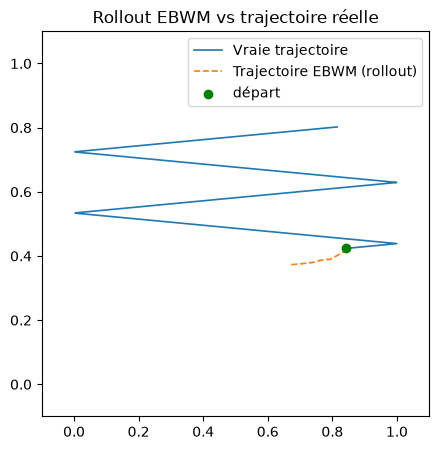

In [ ]:
predicted_traj = rollout_ebwm(ebm_shallow_2, traj, context_len=context_len, n_predict_steps=500, n_steps=50, lr=0.08)

n_total = context_len + 500  # cohérent avec n_predict_steps=500

plt.figure(figsize=(5, 5))
plt.plot(traj[:n_total, 0], traj[:n_total, 1], 
         label="Vraie trajectoire", color="tab:blue", lw=1.2)
plt.plot(predicted_traj[:, 0].detach().numpy(), predicted_traj[:, 1].detach().numpy(), 
         label="Trajectoire EBWM (rollout)", color="tab:orange", lw=1.2, linestyle="--")
plt.scatter(*predicted_traj[0], c="green", zorder=5, label="départ")
plt.xlim(-0.1, 1.1); plt.ylim(-0.1, 1.1)
plt.legend()
plt.title("Rollout EBWM vs trajectoire réelle")
plt.show()

In [26]:
print(predicted_traj.shape)

torch.Size([303, 2])


Dans la théorie, tout semble bien se passer. La loss décroit progressivement,E_pos tend vers -3 et E_neg tend vers 3. DOnc il y a bien un démarquage entre les positifs et les négatifs.

Cependant comme on peut le voir juste en haut, le modèle n'a pas encore cerné le mouvement. Pour cerner le mouvemen il doit intégrer 3 choses : la direction de la vitesse (l'angle), son amplitude et les effets de rebond qui incarne tout une physique newtonienne.

In [70]:
ebm_shallow_3 = EBM(input_dim=input_dim, hidden_dims=[64])
train_ball_ebm(ebm_shallow_3, traj, reg_weight=0.001, n_epochs=10000)

epoch     0 | loss 1.0319 | E_pos 0.119 | E_neg 0.087 | E_neg/E_pos 0.732
epoch   200 | loss 0.9916 | E_pos -0.009 | E_neg -0.000 | E_neg/E_pos 0.010
epoch   400 | loss 0.9887 | E_pos -0.008 | E_neg 0.003 | E_neg/E_pos -0.343
epoch   600 | loss 0.9880 | E_pos -0.004 | E_neg 0.008 | E_neg/E_pos -1.829
epoch   800 | loss 0.9872 | E_pos 0.004 | E_neg 0.017 | E_neg/E_pos 4.385
epoch  1000 | loss 0.9828 | E_pos -0.019 | E_neg -0.002 | E_neg/E_pos 0.114
epoch  1200 | loss 0.9707 | E_pos -0.008 | E_neg 0.022 | E_neg/E_pos -2.813
epoch  1400 | loss 0.2117 | E_pos -1.336 | E_neg 3.720 | E_neg/E_pos -2.784
epoch  1600 | loss 0.2454 | E_pos -3.075 | E_neg 3.307 | E_neg/E_pos -1.075
epoch  1800 | loss 0.2064 | E_pos -2.990 | E_neg 2.788 | E_neg/E_pos -0.932
epoch  2000 | loss 0.2214 | E_pos -2.761 | E_neg 2.623 | E_neg/E_pos -0.950
epoch  2200 | loss 0.2282 | E_pos -2.756 | E_neg 2.764 | E_neg/E_pos -1.003
epoch  2400 | loss 0.0583 | E_pos -2.621 | E_neg 3.642 | E_neg/E_pos -1.389
epoch  2600 | lo

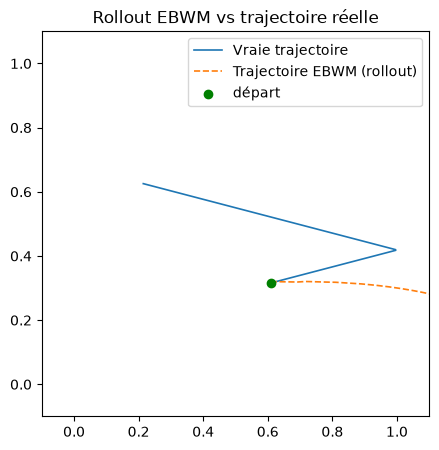

In [71]:
predicted_traj = rollout_ebwm(ebm_shallow_3, traj, context_len=context_len, n_predict_steps=150)

plt.figure(figsize=(5, 5))
plt.plot(traj[:context_len+150, 0], traj[:context_len+150, 1], 
         label="Vraie trajectoire", color="tab:blue", lw=1.2)
plt.plot(predicted_traj[:, 0].detach().numpy(), predicted_traj[:, 1].detach().numpy(), 
         label="Trajectoire EBWM (rollout)", color="tab:orange", lw=1.2, linestyle="--")
plt.scatter(*predicted_traj[0], c="green", zorder=5, label="départ")
plt.xlim(-0.1, 1.1); plt.ylim(-0.1, 1.1)
plt.legend()
plt.title("Rollout EBWM vs trajectoire réelle")
plt.show()

Ici j'ai augmenté le nombre d'époque. Et on voit que le modèle commence à intégrer le vecteur vitesse éssentielle pour la compréhension du mouvement.

10.000 époques pour ne cerner que la vitesse et encore, l'angle est erronné.

Il y a cependant une chose importante à vérifier. Au lieu d'augmenter le nombre d'époque, il se peut que c'est la taille des données qu'il faut augmenter.

C'ette idée est pertinente car un modèle qui a vu un échantillon représentatif fin sera toujours meilleurs qu'un autre qui a vu un échantillon moins représentatif même si on réinjecte ces données un grand nombre de fois.

Tout cette digression c'est pour vous dire que j'ai une idée qui fait sens, je vais vais affiner la trajectoire apprise par le modèle en augmentant certes le nombre de données mais surtout en prenant un dt petit afin de capturer plus de frame et en passant je prendrai un speed (vitesse) moindre afin de ralentir le mouvement, ainsi donc le modèle aura le temps de bien voir la balle se déplacer. 

Alors là franchement, je crois que suis fan de moi même !

In [74]:
traj_fine = simulate_bouncing_ball(n_steps=5000,speed = 0.01, dt=0.002, box=(0.0, 1.0), seed=None)

In [76]:
ctx, true_next = make_positive_pairs(traj_fine)
print(ctx.shape, true_next.shape)

torch.Size([4997, 6]) torch.Size([4997, 2])


In [78]:
ebm_shallow_4 = EBM(input_dim=input_dim, hidden_dims=[64])
false_next = sample_negatives_ball(ebm_shallow_4,ctx)
print(false_next.size())

torch.Size([4997, 2])


In [79]:
def train_ball_ebm(ebm, traj, context_len=3, n_epochs=2000, lr=1e-3, reg_weight=0.01, batch_size=64):
    opt = torch.optim.Adam(ebm.parameters(), lr=lr)

    contexts, true_nexts = make_positive_pairs(traj, context_len=context_len)
    n_samples = contexts.shape[0]

    for epoch in range(n_epochs):
        idx = torch.randint(0, n_samples, (batch_size,))
        x_batch = contexts[idx]
        y_pos = true_nexts[idx]

        y_neg = sample_negatives_ball(ebm, x_batch,n_steps=50, noise_scale=0.05)

        E_pos = ebm(x_batch, y_pos)
        E_neg = ebm(x_batch, y_neg)

        contrastive = torch.relu(1.0 + E_pos - E_neg).mean()
        reg = reg_weight * (E_pos**2 + E_neg**2).mean()
        loss = contrastive + reg

        opt.zero_grad()
        loss.backward()
        opt.step()

        if epoch % 200 == 0:
            print(f"epoch {epoch:5d} | loss {loss.item():.4f} | E_pos {E_pos.mean().item():.3f} | E_neg {E_neg.mean().item():.3f} | E_neg/E_pos {(E_neg.mean()/E_pos.mean()).item():.3f}")

In [80]:
train_ball_ebm(ebm_shallow_4, traj_fine, reg_weight=0.001, n_epochs=10000)

epoch     0 | loss 0.9765 | E_pos -0.100 | E_neg -0.076 | E_neg/E_pos 0.764
epoch   200 | loss 0.9744 | E_pos -0.138 | E_neg -0.112 | E_neg/E_pos 0.814
epoch   400 | loss 0.9858 | E_pos -0.011 | E_neg 0.003 | E_neg/E_pos -0.272
epoch   600 | loss 0.9888 | E_pos -0.007 | E_neg 0.004 | E_neg/E_pos -0.564
epoch   800 | loss 0.9916 | E_pos -0.003 | E_neg 0.005 | E_neg/E_pos -1.652
epoch  1000 | loss 0.9852 | E_pos -0.010 | E_neg 0.005 | E_neg/E_pos -0.467
epoch  1200 | loss 0.9879 | E_pos -0.007 | E_neg 0.005 | E_neg/E_pos -0.644
epoch  1400 | loss 0.9839 | E_pos -0.003 | E_neg 0.013 | E_neg/E_pos -5.146
epoch  1600 | loss 0.9845 | E_pos 0.004 | E_neg 0.020 | E_neg/E_pos 4.673
epoch  1800 | loss 0.9808 | E_pos -0.007 | E_neg 0.012 | E_neg/E_pos -1.674
epoch  2000 | loss 0.9866 | E_pos -0.003 | E_neg 0.010 | E_neg/E_pos -2.968
epoch  2200 | loss 0.9863 | E_pos -0.011 | E_neg 0.003 | E_neg/E_pos -0.244
epoch  2400 | loss 0.9829 | E_pos 0.004 | E_neg 0.021 | E_neg/E_pos 5.775
epoch  2600 | lo

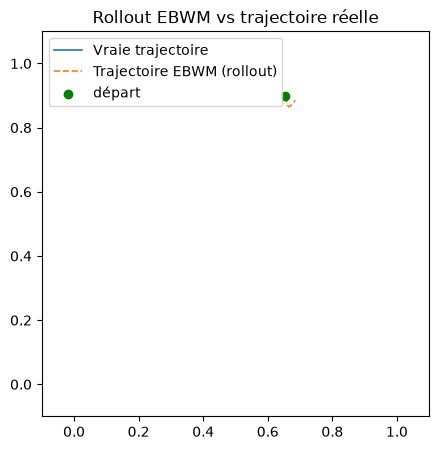

In [81]:
predicted_traj = rollout_ebwm(ebm_shallow_4, traj_fine, context_len=context_len, n_predict_steps=150)

plt.figure(figsize=(5, 5))
plt.plot(traj_fine[:context_len+150, 0], traj_fine[:context_len+150, 1], 
         label="Vraie trajectoire", color="tab:blue", lw=1.2)
plt.plot(predicted_traj[:, 0].detach().numpy(), predicted_traj[:, 1].detach().numpy(), 
         label="Trajectoire EBWM (rollout)", color="tab:orange", lw=1.2, linestyle="--")
plt.scatter(*predicted_traj[0], c="green", zorder=5, label="départ")
plt.xlim(-0.1, 1.1); plt.ylim(-0.1, 1.1)
plt.legend()
plt.title("Rollout EBWM vs trajectoire réelle")
plt.show()